<a href="https://colab.research.google.com/github/Mukundan-T/seqADAGE/blob/main/Py/muk_uADAGE/L1OnlyEcoliModel.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# L1-Only Regularized E. coli Models

### By: Mukundan Thanigaivelan

### October 11, 2026

In this notebook, we will be training E. coli models with the standard ADAGE loss function (mean squared error) in addition to a **L1 regularizer** as experimental models.

## Georgia's comments

- Consider same encoding and decoding activation functions
- Consider reconstruction error as a technical model metric:
  + [Georgia's Article](https://medium.com/@amnahhmohammed/autoencoders-and-testing-their-potential-in-anomaly-detection-09135140fd56)
  + The article, but without the 'faulty' data part, just like at the end with:

```
reconstructions_train = model.predict(train_transformed)
reconstruction_errors_normal_train = np.mean(np.abs(train_transformed - reconstructions_train), axis=1)

reconstructions_test = model.predict(test_transformed)
reconstruction_errors_normal_test = np.mean(np.abs(test_transformed - reconstructions_test), axis=1)
```

## 0. Connect to GitHub

In [ ]:
!git clone https://github.com/Mukundan-T/seqADAGE.git

Cloning into 'seqADAGE'...
remote: Enumerating objects: 915, done.
remote: Counting objects: 100% (137/137), done.
remote: Compressing objects: 100% (66/66), done.
remote: Total 915 (delta 106), reused 78 (delta 71), pack-reused 778 (from 2)
Receiving objects: 100% (915/915), 59.12 MiB | 20.13 MiB/s, done.
Resolving deltas: 100% (525/525), done.


In [ ]:
%cd seqADAGE/Py/muk_transfer_learning

/content/seqADAGE/Py/muk_transfer_learning


In [ ]:
!pip install -qq tensorflow keras statsmodels seaborn keras_tuner

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 129.4/129.4 kB 14.2 MB/s eta 0:00:00


## 1. Loading classes & modules

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import sys, pathlib
sys.path.insert(0, str(pathlib.Path.cwd().parent))

In [ ]:
# ADAGE
from adage import Adage as ad, SeqAdage, LinkedAE

# Data Analysis
import pandas as pd
import numpy as np
import keras

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns

# Miscellaneous
import zipfile
import time
import json
import tensorflow as tf
from types import SimpleNamespace

In [ ]:
# check CPU and GPU available in runtime
print("Num CPUs Available: ", len(tf.config.list_physical_devices('CPU')))
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))
print(tf.test.is_built_with_cuda())

Num CPUs Available:  1
Num GPUs Available:  1
True


## 2. L1 E. coli ADAGE

Hyperparameter search results:

* Units: 40
* Dropout: 0
* Activation 1: CeLU
* Activation 2: Sigmoid
* Shuffle: True
* Initialization: glorot_normal
* kl1: 0.005
* kl2: 0
* lr: 0.031
* bs: 30
* mm: 0.8
* Tied: True

### 2a. Find and save optimal model hyperparameters

In [ ]:
# Load filtered and re-normalized data
filename = '/content/drive/My Drive/Comp-Bio-Projs-S26/data/muk-in-use/ecmg_lcn01_medmean_normal_muk.csv'

filtered_df = pd.read_csv(filename, index_col = 0)
filtered_df.shape

(3608, 10233)

In [ ]:
# Find optimal hyperparameter values
model_trainer = SeqAdage.SeqAdage(filename)
best_hps, tuner = model_trainer.tune_model(
  seed = 42,
  k2 = [0, 0, 1],
  d = [0, 0, 1]
)

Trial 90 Complete [00h 01m 42s]
val_loss: 13.875106811523438

Best val_loss So Far: 0.009419454261660576
Total elapsed time: 00h 23m 12s
Results summary
Results in /content/drive/My Drive/Comp-Bio-Projs-S26/data/muk-in-use/ecmg_lcn01_medmean_normal_muk_42
Showing 10 best trials
Objective(name="val_loss", direction="min")

Trial 0072 summary
Hyperparameters:
units: 60
dropout: 0.0
act1: celu
act2: tanh
shuffle: False
init: glorot_uniform
kl1: 0.0
kl2: 0.0
lr: 0.041
bs: 15
mm: 0.30000000000000004
tied: 1
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 2
tuner/round: 2
tuner/trial_id: 0067
Score: 0.009419454261660576

Trial 0050 summary
Hyperparameters:
units: 10
dropout: 0.0
act1: tanh
act2: celu
shuffle: False
init: glorot_normal
kl1: 0.0
kl2: 0.0
lr: 0.061
bs: 55
mm: 0.5
tied: 0
tuner/epochs: 50
tuner/initial_epoch: 17
tuner/bracket: 3
tuner/round: 3
tuner/trial_id: 0046
Score: 0.011136543937027454

Trial 0088 summary
Hyperparameters:
units: 10
dropout: 0.0
act1: sigmoid
act2: 

In [ ]:
# Optimal hyperparameters - decide based on nonzero l1 regularization value (bs)
best_hps[17].values

{'units': 40,
 'dropout': 0.0,
 'act1': 'celu',
 'act2': 'sigmoid',
 'shuffle': True,
 'init': 'glorot_normal',
 'kl1': 0.005,
 'kl2': 0.0,
 'lr': 0.031,
 'bs': 30,
 'mm': 0.8,
 'tied': 1,
 'tuner/epochs': 50,
 'tuner/initial_epoch': 17,
 'tuner/bracket': 2,
 'tuner/round': 2,
 'tuner/trial_id': '0068'}

In [ ]:
# Save optimal model hyperparameters
optimal_hps = {param: val for param, val in best_hps[17].values.items() if not param.startswith('tuner')}
with open('/content/drive/My Drive/Mukundan - Senior Project/L1 Models/ec_L1_model_hps.json', "w") as f:
  json.dump(optimal_hps, f)

### 2b. Train, choose, and save optimal models

In [ ]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/L1 Models/ec_L1_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

# Train models
l1_models = {}
ec_objs = []
seeds = list(range(75))

for seed in seeds:
  sa = SeqAdage.SeqAdage(
    filename,
    seed = seed + 100,
    enc_dim = optimal_hps['units'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    act = optimal_hps['act1'],
    act2 = optimal_hps['act2'],
    tied = optimal_hps['tied'],
    epochs = 50,
    init = optimal_hps['init'],
    batch_size = optimal_hps['bs'],
    dropout = optimal_hps['dropout'],
    mm = optimal_hps['mm'],
    lr = optimal_hps['lr']
  )
  sa.train_model()
  temp = ad.Adage(sa.autoencoder, sa.history, sa.all_comp)

  ec_objs.append(sa)
  l1_models[seed] = temp

Streaming output truncated to the last 5000 lines.
Epoch 26/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0240 - val_loss: 0.0248
Epoch 27/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0238 - val_loss: 0.0246
Epoch 28/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0237 - val_loss: 0.0245
Epoch 29/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0235 - val_loss: 0.0243
Epoch 30/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0234 - val_loss: 0.0242
Epoch 31/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0233 - val_loss: 0.0241
Epoch 32/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0232 - val_loss: 0.0240
Epoch 33/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0231 - val_loss: 0.0240
Epoch 34/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0231 - val_loss: 0.0239
Epoch 35/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0230 - val_loss: 0.0239
Epoch 36/50
123/123 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.0230 - val_loss:

In [ ]:
# Create enrichment dataframes
kegg_dfs = {}

for seed in l1_models.keys():
  ec_kegg_ps = l1_models[seed].set_kegg(
    '/content/drive/My Drive/Comp-Bio-Projs-S26/data/muk-in-use/ec_kegg_pathways.txt'
  )
  kegg_dfs[seed] = ec_kegg_ps

In [ ]:
# Save sum of p-values and pathways to lists
p_val_sums = []
path_info = []

for df in kegg_dfs.values():
  p_val_sums.append(df.sum().sum())
  path_info.append(df.columns[(df > 1.5).any()].tolist())

In [ ]:
# Inspect p-values
p_val_sums

[np.float64(496.9294532656164),
 np.float64(577.1238810932109),
 np.float64(422.9978418946157),
 np.float64(463.1349816837077),
 np.float64(435.05228305400703),
 np.float64(416.45329793198164),
 np.float64(559.4760584662257),
 np.float64(510.8510918417711),
 np.float64(372.99248479182256),
 np.float64(438.52903602834203),
 np.float64(446.330743774884),
 np.float64(506.5005169086787),
 np.float64(362.3320903107882),
 np.float64(769.4526508082627),
 np.float64(385.4976416534854),
 np.float64(430.3478135437574),
 np.float64(470.6368084336448),
 np.float64(355.5660676666663),
 np.float64(348.77935552707135),
 np.float64(321.92893060261054),
 np.float64(401.903491671283),
 np.float64(520.3155525126423),
 np.float64(435.1350972560154),
 np.float64(431.90954470160204),
 np.float64(334.4789973929601),
 np.float64(286.4495646222367),
 np.float64(339.7019877706626),
 np.float64(473.1453781977714),
 np.float64(429.83253759053093),
 np.float64(313.254946037007),
 np.float64(509.3686019440547),
 np

In [ ]:
# Save all best models
for seed in seeds:
  ec_objs[seed].autoencoder.save(
    f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/ec_best_model{seed+1}.keras'
  )

In [ ]:
# Save KEGG enrichment matrices for the best models
for seed in seeds:
  kegg_dfs[seed].to_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/kegg_dfs/ec_kegg_ps{seed+1}.csv',
  )

### 2c. Load optimal models

In [ ]:
model_filenames = [
  f'/content/drive/My Drive/Mukundan - Senior Project/Baseline Models/ec_best_model{i+1}.keras'
  for i in range(2)
]

In [ ]:
# Load hyperparameters
with open('/content/drive/My Drive/Mukundan - Senior Project/Data/ec_control_model_hps.json', 'r') as f:
  optimal_hps = json.load(f)

In [ ]:
loaded_models = []

for file in model_filenames:
  # Create autoencoder object
  ae = LinkedAE.LinkedAE(
    encoding_dim = optimal_hps['units'],
    act2 = optimal_hps['act2'],
    d = optimal_hps['dropout'],
    kl1 = optimal_hps['kl1'],
    kl2 = optimal_hps['kl2'],
    init = optimal_hps['init']
  )
  ae(tf.zeros((1, filtered_df.shape[0])))

  # Pull model weights
  with zipfile.ZipFile(file) as z:
    z.extract('model.weights.h5')

  # Load saved weights
  ae.load_weights('model.weights.h5')

  # Create ADAGE object
  adage = ad.Adage(
    autoencoder = ae,
    history = SimpleNamespace(
      history = {
        'loss': [],
        'val_loss': [],
      }
    ),
    train_comp = pd.read_csv(
      '/content/drive/My Drive/Comp-Bio-Projs-S26/data/muk-in-use/ecmg_lcn01_medmean_normal_muk.csv',
      index_col = 0
    ),
  )

  # Add model to list
  loaded_models.append(adage)

### 2d. Loss curves and weight distributions

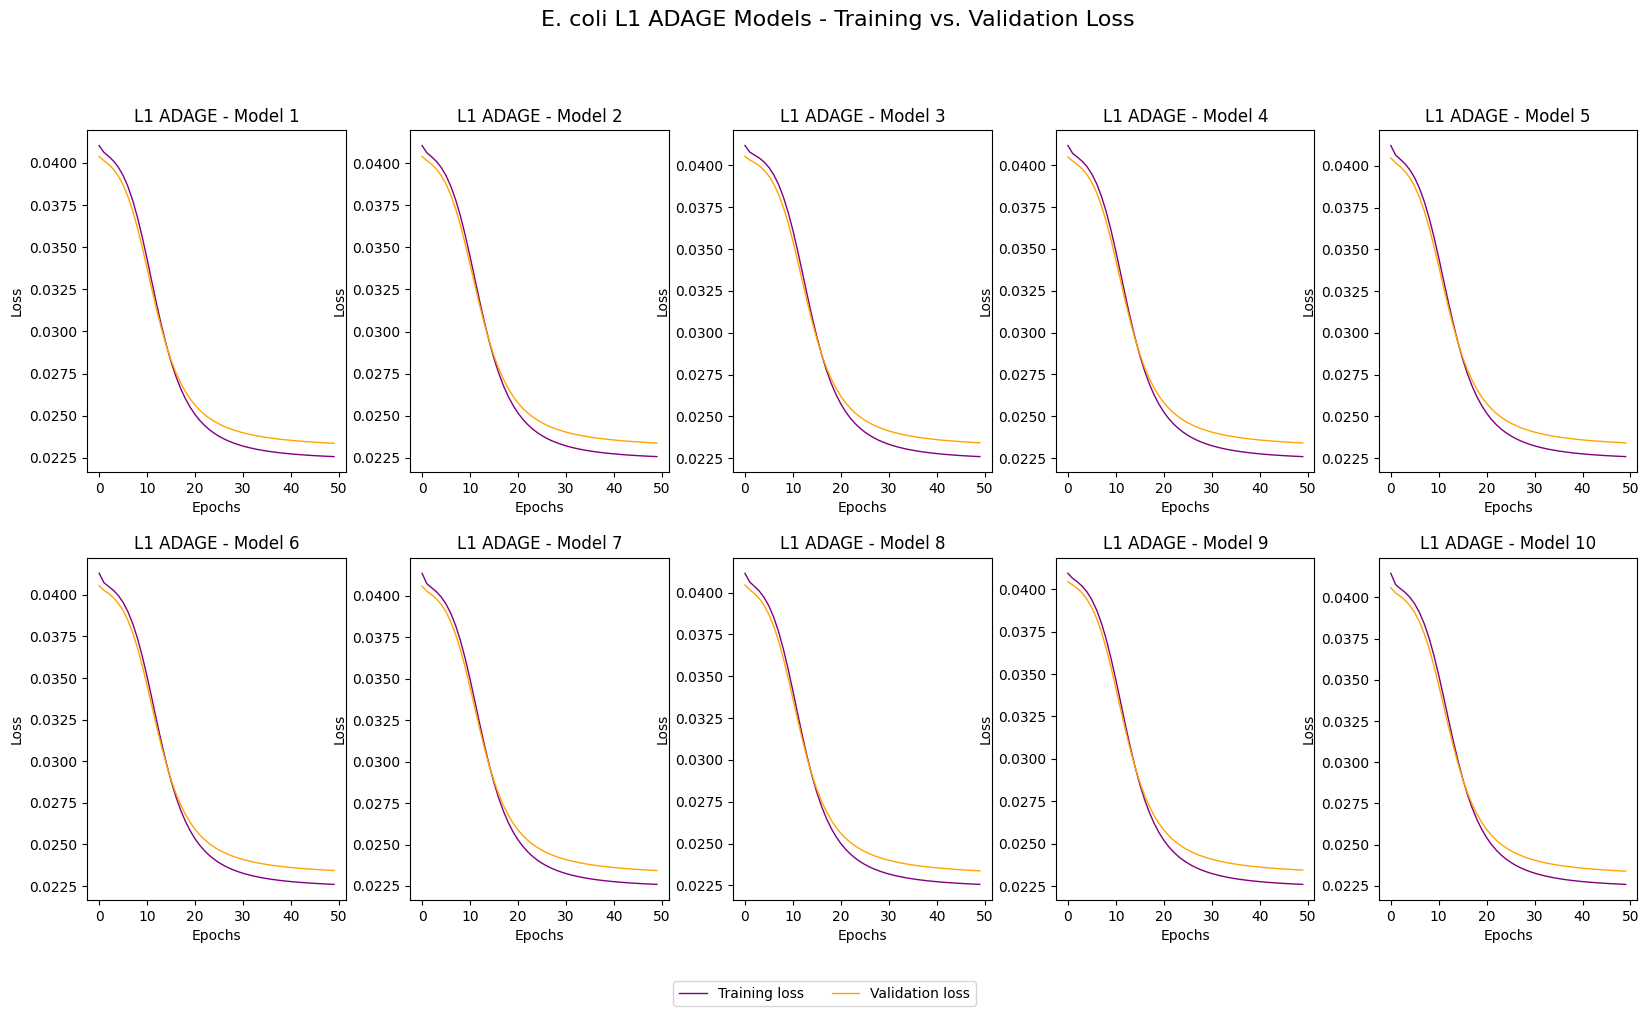

In [ ]:
plot_titles = [
  f'L1 ADAGE - Model {i+1}'
  for i in range(10)
]

fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli L1 ADAGE Models - Training vs. Validation Loss',
  fontsize = 16,
  y = 1
)

# Only plot curves for first 10 models - rest will be similar
for i in range(2):
  for j in range(5):
    ax[i, j].plot(
      range(50),
      l1_models[5*i + j].loss,
      linewidth = 1,
      color = 'purple',
      label = 'Training loss'
    )
    ax[i, j].plot(
      range(50),
      l1_models[5*i + j].val_loss,
      linewidth = 1,
      color = 'orange',
      label = 'Validation loss'
    )
    ax[i, j].set(
      title = plot_titles[5*i + j],
      xlabel = 'Epochs',
      ylabel = 'Loss'
    )

handles, labels = ax[0, 0].get_legend_handles_labels()
fig.legend(
  handles,
  labels,
  loc = 'lower center',
  ncol = 2,
  fontsize = 10
)

fig.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L1 Models/Plots/ec_l1_loss.png',
  dpi = 300,
  bbox_inches = 'tight'
)

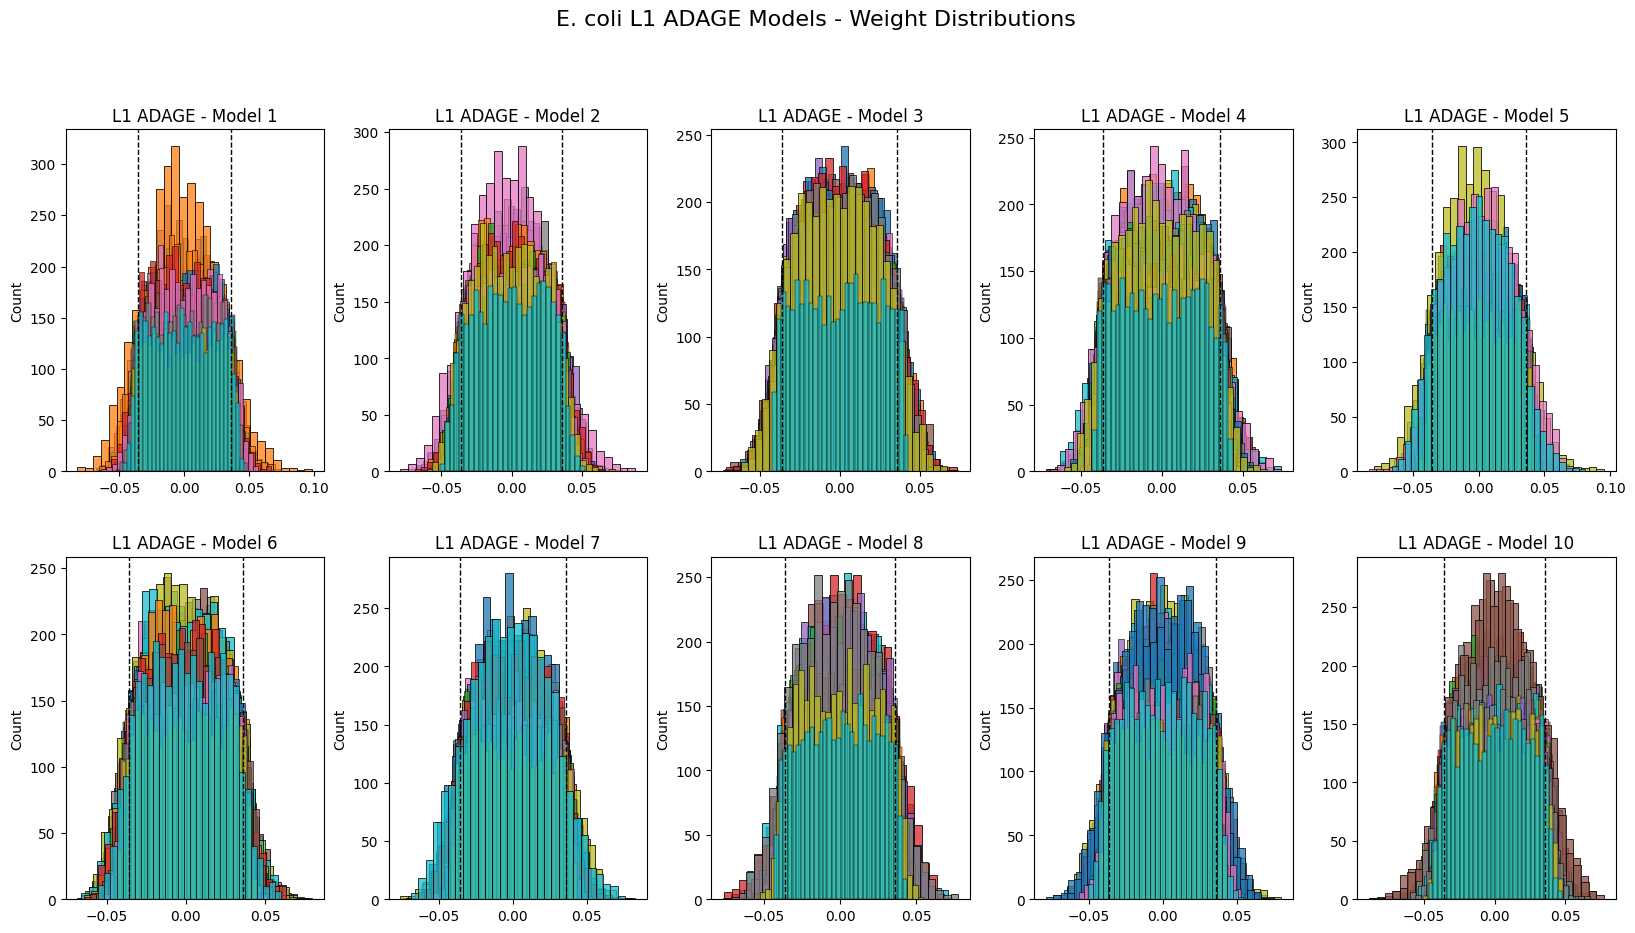

In [ ]:
plot_titles = [
  f'L1 ADAGE - Model {i+1}'
  for i in range(10)
]
fig, ax = plt.subplots(2, 5, figsize = (20, 10))
fig.subplots_adjust(hspace = 0.25, wspace = 0.25)

fig.suptitle(
  'E. coli L1 ADAGE Models - Weight Distributions',
  fontsize = 16,
  y = 1
)

for i in range(2):
  for j in range(5):
    for node in range(optimal_hps['units']):
      weights = np.asarray(l1_models[5*i + j].weights.T[node])
      weights = weights[np.isfinite(weights)]

      # Skip empty arrays
      if len(weights) == 0:
        continue

      # Skip constant distributions
      if np.min(weights) == np.max(weights):
        continue

      # Each hidden node weight distribution
      sns.histplot(
        weights,
        ax = ax[i, j],
        bins = 30,
        kde = False
      )

    all_weights = np.asarray(l1_models[5*i + j].weights.T).flatten()
    all_weights = all_weights[np.isfinite(all_weights)]
    cutoff = np.std(all_weights) * 1.5

    ax[i, j].axvline(
        x = cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].axvline(
        x = -cutoff,
        color = 'black',
        linestyle = '--',
        linewidth = 1
    )
    ax[i, j].set(title = plot_titles[5*i + j])

fig.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L1 Models/Plots/ec_l1_weight_dists.png',
  dpi = 300,
  bbox_inches = 'tight'
)

### 2e. Perform KEGG analysis

In [ ]:
# Load KEGG p-value matrices
kegg_ps = [
  pd.read_csv(
    f'/content/drive/My Drive/Mukundan - Senior Project/L1 Models/kegg_dfs/ec_kegg_ps{i+1}.csv'
  )
  for i in range(75)
]

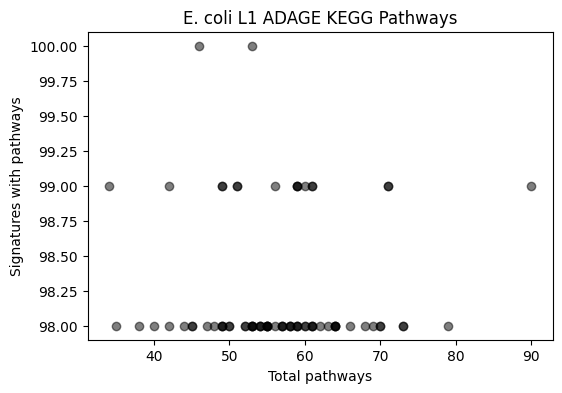

In [ ]:
# Plot KEGG pathways
plt.figure(figsize = (6, 4))

for kegg_vals in kegg_ps:
  x = ((kegg_vals > 1.5).sum(0) > 0).sum()
  y = ((kegg_vals > 1.5).sum(1) > 0).sum()
  plt.scatter(x, y, alpha = 0.5, color = "black")

plt.title('E. coli L1 ADAGE KEGG Pathways')
plt.xlabel('Total pathways')
plt.ylabel('Signatures with pathways')

plt.savefig(
  '/content/drive/MyDrive/Mukundan - Senior Project/L1 Models/Plots/ec_l1_kegg.png',
  dpi = 300,
  bbox_inches = 'tight'
)